# 04_ROCOv2_Preprocessing_Pipeline

**Purpose:** Build and validate the reusable image + text preprocessing pipeline
that later modeling notebooks (baselines and beyond) will depend on. This
notebook does **not** train any model.

It consumes the fixed, leakage-audited splits produced by
`02_ROCOv2_Dataset_Preparation.ipynb` (independently verified by
`03_Split_Integrity_Audit.ipynb`) and produces:

- An image-level integrity audit (dimensions, color mode, corruption check)
  read directly from the original ROCOv2 ZIP archives — **no images are
  extracted or copied to disk in bulk.**
- A deterministic image transform pipeline (train augmentation vs.
  eval-time deterministic transform).
- Per-channel pixel normalization statistics computed from the **Train split
  only**.
- A caption tokenization pipeline built on a fixed, named PubMedBERT
  checkpoint (never silently substituted).
- A single `torch.utils.data.Dataset` class serving image, text, or
  multimodal samples from the same underlying prepared metadata, so unimodal
  and multimodal baselines in later notebooks share one audited loading path
  instead of three divergent ones.
- End-to-end smoke tests: batch shape checks, label/ID alignment checks, and
  a shuffle-determinism check.

### Fixed protocol (carried over from Notebooks 02/03 — not re-decided here)
- **Train** → used for training and for every statistic fit in this notebook
  (normalization mean/std, caption-length percentiles).
- **Validation (= Calibration)** → held out from any statistic-fitting
  decision in this notebook. It is loaded only to prove the pipeline works
  on it identically to Train, never to inform a preprocessing choice.
- **Test** → untouched final evaluation split. Loaded only for a pipeline
  smoke test (confirming it loads correctly), never inspected for any
  statistic that could influence design choices.
- No repartitioning. No relabeling. Original ROCOv2 ZIP archives are opened
  read-only and never modified.

### Dependency
Run `02_ROCOv2_Dataset_Preparation.ipynb` first (hard requirement — this
notebook raises `FileNotFoundError` otherwise). Running
`03_Split_Integrity_Audit.ipynb` beforehand is strongly recommended but not
re-enforced here, since 03 already re-verifies 02's output independently.

### Reuse policy
Expensive, idempotent audit artifacts (image property audit, channel
statistics, caption-length statistics) are **reused if already present on
disk** rather than recomputed, so this notebook is safely re-runnable.
`preprocessing_config.json` is treated as an **authoritative, frozen
record** (like `label_mapping.json` from Notebook 02) and is protected from
silent overwrite — the same convention Notebook 02 already established.


In [1]:
# ============================================================
# CELL 1 — CONFIGURATION AND REPRODUCIBILITY
# ============================================================

import os
import io
import sys
import json
import random
import warnings
import platform
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Google Colab / Google Drive
# ------------------------------------------------------------
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

# ------------------------------------------------------------
# Explicit project paths (no hard-coded temp paths)
# ------------------------------------------------------------
ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"
EDA_DIR = ROCO_ROOT / "EDA"
AUDIT_DIR = EDA_DIR / "split_integrity_audit"

PREPROCESSING_DIR = PREPARED_DIR / "Preprocessing"
FIGURES_DIR = PREPROCESSING_DIR / "figures"
PREPROCESSING_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Inputs from Notebook 02 (read-only)
TRAIN_PREPARED_PATH = PREPARED_DIR / "train_prepared.csv"
VALID_PREPARED_PATH = PREPARED_DIR / "validation_prepared.csv"
TEST_PREPARED_PATH = PREPARED_DIR / "test_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"
DATASET_CONFIG_PATH = PREPARED_DIR / "dataset_config.json"

# Original ROCOv2 image ZIP archives (read-only, never extracted in bulk)
IMAGE_ZIP_FILES = {
    "train": ROCO_ROOT / "Train" / "Images" / "train_images.zip",
    "validation": ROCO_ROOT / "Validation" / "Images" / "valid_images.zip",
    "test": ROCO_ROOT / "Test" / "Images" / "test_images.zip",
}

PREPARED_PATHS = {
    "train": TRAIN_PREPARED_PATH,
    "validation": VALID_PREPARED_PATH,
    "test": TEST_PREPARED_PATH,
}

# ------------------------------------------------------------
# Output artifact paths produced by THIS notebook
# ------------------------------------------------------------
IMAGE_PROPERTY_AUDIT_PATH = PREPROCESSING_DIR / "image_property_audit.csv"
TRAIN_CHANNEL_STATS_PATH = PREPROCESSING_DIR / "train_channel_statistics.json"
CAPTION_LENGTH_STATS_PATH = PREPROCESSING_DIR / "caption_length_statistics.csv"
PREPROCESSING_CONFIG_PATH = PREPROCESSING_DIR / "preprocessing_config.json"
SAMPLE_BATCH_FIGURE_PATH = FIGURES_DIR / "sample_batch_grid.png"
SMOKE_TEST_LOG_PATH = PREPROCESSING_DIR / "pipeline_smoke_test_log.json"

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
SEED = 42

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_global_seed(SEED)

print("=" * 80)
print("NOTEBOOK 04 — PREPROCESSING PIPELINE")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("PREPROCESSING_DIR:", PREPROCESSING_DIR)
print("Random seed:", SEED)


Mounted at /content/drive
Google Drive available.
NOTEBOOK 04 — PREPROCESSING PIPELINE
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
PREPROCESSING_DIR: /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing
Random seed: 42


## 1. Verify required inputs from Notebook 02 exist

This notebook must not silently fabricate or substitute anything the
data-preparation stage was responsible for. Stop immediately if any
required artifact is missing.

In [2]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "train_prepared.csv": TRAIN_PREPARED_PATH,
    "validation_prepared.csv": VALID_PREPARED_PATH,
    "test_prepared.csv": TEST_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
    "dataset_config.json": DATASET_CONFIG_PATH,
}

missing_inputs = [
    f"{name}: {path}"
    for name, path in required_inputs.items()
    if not path.exists()
]

if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 04 input artifacts are missing:\n\n"
        + "\n".join(missing_inputs)
        + "\n\n"
        "Run 02_ROCOv2_Dataset_Preparation.ipynb first. "
        "Do not continue until the missing artifacts are generated."
    )

for name, path in IMAGE_ZIP_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Original image ZIP missing for {name}: {path}")

# Soft, non-blocking check: recommend (not require) that Notebook 03 has run.
if not (AUDIT_DIR / "split_statistics.csv").exists():
    print(
        "WARNING — Notebook 03 (Split Integrity Audit) output was not found at\n"
        f"  {AUDIT_DIR / 'split_statistics.csv'}\n"
        "This notebook does not hard-require it, but running 03 before any "
        "modeling notebook is strongly recommended."
    )
else:
    print("Notebook 03 audit artifacts found — splits were independently audited.")

print("\nPASS — Required Notebook 02 artifacts and original image ZIPs exist.")
for name, path in required_inputs.items():
    print(f"{name:30s}: {path}")


Notebook 03 audit artifacts found — splits were independently audited.

PASS — Required Notebook 02 artifacts and original image ZIPs exist.
train_prepared.csv            : /content/drive/MyDrive/ROCOv2/Prepared/train_prepared.csv
validation_prepared.csv       : /content/drive/MyDrive/ROCOv2/Prepared/validation_prepared.csv
test_prepared.csv             : /content/drive/MyDrive/ROCOv2/Prepared/test_prepared.csv
label_mapping.json            : /content/drive/MyDrive/ROCOv2/Prepared/label_mapping.json
dataset_config.json           : /content/drive/MyDrive/ROCOv2/Prepared/dataset_config.json


## 2. Load prepared splits and the authoritative label order

Label order is read from `label_mapping.json`, never re-derived or
re-ordered here — Notebook 02 declared it authoritative and Notebook 03
already verified it round-trips from disk correctly.

In [3]:
# ============================================================
# CELL 3 — LOAD PREPARED SPLITS AND LABEL MAPPING
# ============================================================

split_dfs = {
    split_name: pd.read_csv(path)
    for split_name, path in PREPARED_PATHS.items()
}

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."

# label_mapping.json stores {CUI: column_index}; prepared columns are named
# "label_{CUI}" (see 02_ROCOv2_Dataset_Preparation.ipynb, Cell 10).
LABEL_COLUMNS = [
    f"label_{cui}"
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

for split_name, df in split_dfs.items():
    missing_label_cols = set(LABEL_COLUMNS) - set(df.columns)
    if missing_label_cols:
        raise ValueError(f"{split_name}: missing label columns {sorted(missing_label_cols)}")

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen",
    "C0002978": "Angiogram",
    "C0006141": "Breast",
    "C0023216": "Lower Extremity",
    "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis",
    "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium",
    "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography",
    "C0041618": "Ultrasonography",
    "C0205106": "Transverse",
    "C0205129": "Sagittal",
    "C0817096": "Chest",
    "C1140618": "Upper Extremity",
    "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior",
    "C1999039": "Anterior-Posterior",
}

print("=" * 80)
print("PREPARED SPLIT SIZES")
print("=" * 80)
for split_name, df in split_dfs.items():
    print(f"{split_name.capitalize():12s}: {len(df):,} rows")

print("\nLabel order (authoritative, from label_mapping.json):")
for cui, index in sorted(label_mapping.items(), key=lambda kv: kv[1]):
    print(f"  {index:02d} | {cui} | {CANONICAL_LABEL_NAMES.get(cui, '(name unavailable)')}")


PREPARED SPLIT SIZES
Train       : 59,666 rows
Validation  : 9,819 rows
Test        : 9,870 rows

Label order (authoritative, from label_mapping.json):
  00 | C0000726 | Abdomen
  01 | C0002978 | Angiogram
  02 | C0006141 | Breast
  03 | C0023216 | Lower Extremity
  04 | C0024485 | Magnetic Resonance Imaging
  05 | C0030797 | Pelvis
  06 | C0032743 | Positron-Emission Tomography
  07 | C0037303 | Bone structure of cranium
  08 | C0037949 | Vertebral column
  09 | C0040405 | X-Ray Computed Tomography
  10 | C0041618 | Ultrasonography
  11 | C0205106 | Transverse
  12 | C0205129 | Sagittal
  13 | C0817096 | Chest
  14 | C1140618 | Upper Extremity
  15 | C1306645 | Plain x-ray
  16 | C1996865 | Postero-Anterior
  17 | C1999039 | Anterior-Posterior


## 3. Read images directly from the original ZIP archives

Original archives are opened read-only. Nothing is extracted to disk in
bulk. `Image_Member` (written by Notebook 02) already gives the resolved
in-archive path for every sample, so no re-resolution logic is duplicated
here.

In [4]:
# ============================================================
# CELL 4 — LAZY, WORKER-SAFE ZIP IMAGE READER (with verified overlap fallback)
# ============================================================
# zipfile.ZipFile handles are not safely shared across DataLoader worker
# processes (fork or spawn). Each worker must open its own handle lazily on
# first access rather than sharing one opened in the main process.
#
# Some ROCOv2 archive entries trip CPython's "overlapped entries" zipfile
# safety check (an anti zip-bomb heuristic added in recent CPython security
# patches) even though the underlying entry is an ordinary, valid image —
# this is a documented source of false positives on legitimately-packed
# archives, not evidence the ROCOv2 archive itself is malicious. When
# stdlib zipfile refuses an entry, this reader falls back to the system
# `unzip` utility (which does not apply that heuristic) to extract the same
# bytes, and the caller (Cell 5) independently re-verifies the result still
# decodes as a valid image before accepting it. Every fallback use is
# counted and reported — never silently absorbed.

import shutil
import subprocess

_UNZIP_AVAILABLE = shutil.which("unzip") is not None

class ZipImageReader:
    def __init__(self, zip_path):
        self.zip_path = Path(zip_path)
        self._zf = None
        self.fallback_count = 0

    def _ensure_open(self):
        if self._zf is None:
            self._zf = zipfile.ZipFile(self.zip_path, "r")
        return self._zf

    def _read_via_unzip(self, member):
        if not _UNZIP_AVAILABLE:
            raise RuntimeError(
                "System 'unzip' utility not found — required as a fallback "
                "for archive entries that trip zipfile's overlap check. "
                "Install it (e.g. `!apt-get install -y unzip` on Colab)."
            )
        result = subprocess.run(
            ["unzip", "-p", str(self.zip_path), member],
            capture_output=True,
            check=True,
        )
        return result.stdout

    def read_bytes(self, member):
        try:
            zf = self._ensure_open()
            return zf.read(member)
        except zipfile.BadZipFile as exc:
            raw_bytes = self._read_via_unzip(member)
            self.fallback_count += 1
            print(
                f"NOTE — {self.zip_path.name}:{member} required the 'unzip' "
                f"fallback (zipfile raised: {exc})."
            )
            return raw_bytes

    def __getstate__(self):
        # Never pickle an open file handle across process boundaries.
        state = self.__dict__.copy()
        state["_zf"] = None
        return state

    def __setstate__(self, state):
        self.__dict__.update(state)


zip_readers = {
    split_name: ZipImageReader(path)
    for split_name, path in IMAGE_ZIP_FILES.items()
}

# Smoke-check the reader on one real sample per split before relying on it.
for split_name, df in split_dfs.items():
    sample_row = df.iloc[0]
    raw_bytes = zip_readers[split_name].read_bytes(sample_row["Image_Member"])
    assert len(raw_bytes) > 0, f"{split_name}: read zero bytes for {sample_row['Image_Member']}"

print("PASS — Zip image reader verified on one sample per split.")


PASS — Zip image reader verified on one sample per split.


## 4. Section A — Image-level integrity audit

Notebook 03 already confirmed that every `Image_Member` reference exists as
a ZIP entry. It did **not** check whether each entry is actually a decodable,
uncorrupted image, nor did it record dimensions or color mode. This section
performs that pixel-level audit for the first time, reading each image
directly from its ZIP (no bulk extraction).

This is a full scan over every split (not a subsample), because a single
corrupt image reaching a training loop later fails silently mid-epoch —
catching it here, once, is cheap by comparison.

Reused if `image_property_audit.csv` already exists on disk **and** its
`(Split, ID)` coverage exactly matches the current prepared splits — an
existing file that doesn't fully match is treated as stale and
recomputed, rather than trusted just because a file happens to be present
at that path.

In [6]:
# ============================================================
# CELL 5 — IMAGE PROPERTY AND CORRUPTION AUDIT (full scan, reusable)
# ============================================================

try:
    from PIL import Image
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow"], check=True)
    from PIL import Image

REQUIRED_AUDIT_COLUMNS = {
    "Split", "ID", "Image_Member", "Width", "Height", "Mode",
    "Read_Method", "Corrupt", "Error",
}

def _audit_is_stale(existing_df, current_split_dfs):
    # A reused audit is only trustworthy if it (a) was written by the
    # current schema — an older run without, e.g., the Read_Method column
    # cannot be trusted to reflect the current fallback-verified read path
    # — and (b) covers exactly the current (Split, ID) set.
    if not REQUIRED_AUDIT_COLUMNS.issubset(existing_df.columns):
        return True
    expected_pairs = {
        (split_name, sample_id)
        for split_name, df in current_split_dfs.items()
        for sample_id in df["ID"]
    }
    existing_pairs = set(zip(existing_df["Split"], existing_df["ID"]))
    return existing_pairs != expected_pairs

image_property_audit_df = None

if IMAGE_PROPERTY_AUDIT_PATH.exists():
    _candidate_df = pd.read_csv(IMAGE_PROPERTY_AUDIT_PATH)
    if _audit_is_stale(_candidate_df, split_dfs):
        print(
            f"WARNING — existing {IMAGE_PROPERTY_AUDIT_PATH} does not match "
            "the current audit schema and/or (Split, ID) coverage. Treating "
            "it as stale and recomputing rather than silently reusing a "
            "mismatched or outdated audit."
        )
    else:
        print(f"REUSING existing artifact — not recomputing: {IMAGE_PROPERTY_AUDIT_PATH}")
        image_property_audit_df = _candidate_df

if image_property_audit_df is None:
    audit_rows = []

    for split_name, df in split_dfs.items():
        reader = zip_readers[split_name]
        print(f"Scanning {split_name} ({len(df):,} images)...")

        for _, row in df.iterrows():
            member = row["Image_Member"]
            record = {
                "Split": split_name,
                "ID": row["ID"],
                "Image_Member": member,
                "Width": None,
                "Height": None,
                "Mode": None,
                "Read_Method": "zipfile",
                "Corrupt": False,
                "Error": "",
            }
            _fallback_before = reader.fallback_count
            try:
                raw_bytes = reader.read_bytes(member)
                if reader.fallback_count > _fallback_before:
                    record["Read_Method"] = "unzip_fallback"
                with Image.open(io.BytesIO(raw_bytes)) as img:
                    img.verify()
                # verify() invalidates the file pointer; reopen to read metadata.
                with Image.open(io.BytesIO(raw_bytes)) as img:
                    record["Width"], record["Height"] = img.size
                    record["Mode"] = img.mode
            except Exception as exc:
                record["Corrupt"] = True
                record["Error"] = f"{type(exc).__name__}: {exc}"

            audit_rows.append(record)

    image_property_audit_df = pd.DataFrame(audit_rows)
    image_property_audit_df.to_csv(IMAGE_PROPERTY_AUDIT_PATH, index=False)
    print("Saved:", IMAGE_PROPERTY_AUDIT_PATH)

n_corrupt = int(image_property_audit_df["Corrupt"].sum())
if "Read_Method" in image_property_audit_df.columns:
    n_fallback = int((image_property_audit_df["Read_Method"] == "unzip_fallback").sum())
else:
    n_fallback = 0

print("\n" + "=" * 80)
print("IMAGE PROPERTY AUDIT SUMMARY")
print("=" * 80)
display(
    image_property_audit_df.groupby("Split").agg(
        Images=("ID", "count"),
        Corrupt=("Corrupt", "sum"),
        Modes=("Mode", lambda s: sorted(s.dropna().unique().tolist())),
    )
)

if n_fallback:
    print(
        f"\nNOTE — {n_fallback} image(s) required the 'unzip' fallback because "
        "zipfile's overlapped-entries check rejected the normal zipfile read. "
        "Each was independently re-verified as a valid, decodable image before "
        "being accepted (see the 'Read_Method' column)."
    )
    display(
        image_property_audit_df.loc[
            image_property_audit_df["Read_Method"] == "unzip_fallback",
            ["Split", "ID", "Image_Member"],
        ]
    )

if n_corrupt:
    display(image_property_audit_df.loc[image_property_audit_df["Corrupt"], ["Split", "ID", "Image_Member", "Error"]])
    raise AssertionError(
        f"{n_corrupt} corrupt/unreadable image(s) detected (including any that "
        "failed even after the unzip fallback). Do not silently skip these — "
        "resolve at the source before proceeding."
    )

print("\nPASS — Every referenced image opened and decoded successfully in every split.")


WARNING — existing /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/image_property_audit.csv does not match the current audit schema and/or (Split, ID) coverage. Treating it as stale and recomputing rather than silently reusing a mismatched or outdated audit.
Scanning train (59,666 images)...
Scanning validation (9,819 images)...
Scanning test (9,870 images)...
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/image_property_audit.csv

IMAGE PROPERTY AUDIT SUMMARY


,Images,Corrupt,Modes
Split,,,
test,9870,0,"[L, RGB]"
train,59666,0,"[L, RGB]"
validation,9819,0,"[L, RGB]"



PASS — Every referenced image opened and decoded successfully in every split.


## 5. Image size / aspect-ratio distribution and target size decision

The target model input size is picked from the audited dimension
distribution (all splits — inspecting file dimensions is not a
leakage-sensitive decision, unlike fitting normalization statistics or
choosing a max token length, which are Train-only later in this notebook).

`TARGET_IMAGE_SIZE = 224` is used explicitly below because it is the
documented, standard input resolution for the ImageNet-pretrained CNN/ViT
backbones and PubMedBERT-paired vision backbones this thesis's baseline
notebook is expected to use. It is written to `preprocessing_config.json`
as an explicit, named decision — not a silent default buried in transform
code — so later notebooks read it rather than re-deciding it.

In [7]:
# ============================================================
# CELL 6 — IMAGE SIZE DISTRIBUTION AND TARGET SIZE
# ============================================================

size_summary = (
    image_property_audit_df
    .groupby("Split")[["Width", "Height"]]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
)
display(size_summary)

TARGET_IMAGE_SIZE = 224  # explicit, documented decision — see markdown above

aspect_ratios = image_property_audit_df["Width"] / image_property_audit_df["Height"]
print(f"\nAspect ratio (width/height): median={aspect_ratios.median():.3f}, "
      f"5th={aspect_ratios.quantile(0.05):.3f}, 95th={aspect_ratios.quantile(0.95):.3f}")
print(f"\nTARGET_IMAGE_SIZE = {TARGET_IMAGE_SIZE} (square resize target for all splits)")


Width                                                      \
              count        mean         std    min     5%    25%    50%   
Split                                                                     
test         9870.0  690.352077  122.540100  130.0  443.0  644.0  736.0   
train       59666.0  639.589398  142.539677   85.0  358.0  598.0  644.0   
validation   9819.0  689.577656  129.487519  119.0  444.0  642.0  734.0   

                                   Height                                 \
              75%    95%     max    count        mean         std    min   
Split                                                                      
test        750.0  800.0  3770.0   9870.0  632.984600  227.302956  128.0   
train       750.0  800.0  4569.0  59666.0  587.177639  214.929014  127.0   
validation  750.0  800.0  3799.0   9819.0  630.744882  230.563331  166.0   

                                                         
                5%    25%    50%    75%     95%     max  
Split                                                    
test        341.45  489.0  597.0  745.0  1004.0  3164.0  
train       310.00  450.0  558.0  698.0   944.0  5842.0  
validation  340.00  485.0  594.0  744.0  1013.1  3573.0


Aspect ratio (width/height): median=1.149, 5th=0.704, 95th=1.727

TARGET_IMAGE_SIZE = 224 (square resize target for all splits)


## 6. Section A (continued) — Train-only pixel normalization statistics

Per-channel mean/std are fit **exclusively on the Train split**, after
resizing to `TARGET_IMAGE_SIZE` and scaling to `[0, 1]` (the same
transform later applied at load time), matching standard practice. These
statistics are then applied unchanged to Validation/Calibration and Test —
they are never re-fit on those splits, which would leak split-specific
pixel-intensity information into the "fixed" preprocessing definition.

Computed via a streaming sum / sum-of-squares accumulator, so memory use
stays constant regardless of Train split size.

Reused if `train_channel_statistics.json` already exists on disk.

In [8]:
# ============================================================
# CELL 7 — TRAIN-ONLY CHANNEL NORMALIZATION STATISTICS (streaming, reusable)
# ============================================================

# None = use the full Train split. Set to an int for a faster, still-seeded
# subsample if runtime is prohibitive; do not change this silently mid-project.
NORM_STATS_MAX_SAMPLES = None

if TRAIN_CHANNEL_STATS_PATH.exists():
    print(f"REUSING existing artifact — not recomputing: {TRAIN_CHANNEL_STATS_PATH}")
    with open(TRAIN_CHANNEL_STATS_PATH, "r", encoding="utf-8") as f:
        train_channel_stats = json.load(f)
else:
    train_df_for_stats = split_dfs["train"]

    if NORM_STATS_MAX_SAMPLES is not None and NORM_STATS_MAX_SAMPLES < len(train_df_for_stats):
        train_df_for_stats = train_df_for_stats.sample(
            n=NORM_STATS_MAX_SAMPLES, random_state=SEED
        )

    reader = zip_readers["train"]

    pixel_sum = np.zeros(3, dtype=np.float64)
    pixel_sq_sum = np.zeros(3, dtype=np.float64)
    pixel_count = 0

    print(f"Computing channel statistics over {len(train_df_for_stats):,} Train images...")

    for _, row in train_df_for_stats.iterrows():
        raw_bytes = reader.read_bytes(row["Image_Member"])
        with Image.open(io.BytesIO(raw_bytes)) as img:
            img = img.convert("RGB").resize(
                (TARGET_IMAGE_SIZE, TARGET_IMAGE_SIZE), Image.BILINEAR
            )
            arr = np.asarray(img, dtype=np.float64) / 255.0  # (H, W, 3)

        pixel_sum += arr.sum(axis=(0, 1))
        pixel_sq_sum += (arr ** 2).sum(axis=(0, 1))
        pixel_count += arr.shape[0] * arr.shape[1]

    mean = (pixel_sum / pixel_count)
    variance = (pixel_sq_sum / pixel_count) - mean ** 2
    std = np.sqrt(np.clip(variance, a_min=1e-12, a_max=None))

    train_channel_stats = {
        "channel_mean": mean.tolist(),
        "channel_std": std.tolist(),
        "computed_on_split": "train",
        "n_images": int(len(train_df_for_stats)),
        "target_image_size": TARGET_IMAGE_SIZE,
        "seed": SEED,
    }

    with open(TRAIN_CHANNEL_STATS_PATH, "w", encoding="utf-8") as f:
        json.dump(train_channel_stats, f, indent=2)
    print("Saved:", TRAIN_CHANNEL_STATS_PATH)

print("\nTrain-only channel mean (RGB):", train_channel_stats["channel_mean"])
print("Train-only channel std  (RGB):", train_channel_stats["channel_std"])

assert train_channel_stats["computed_on_split"] == "train", (
    "Normalization statistics must be computed on the Train split only."
)


REUSING existing artifact — not recomputing: /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/train_channel_statistics.json

Train-only channel mean (RGB): [0.3411375121788792, 0.3471113800019527, 0.34902790001484524]
Train-only channel std  (RGB): [0.29433716104150287, 0.2970567979066339, 0.29809280909672176]


## 7. Image transform pipeline (train augmentation vs. deterministic eval)

Augmentation is applied to **Train only**. Validation/Calibration and Test
use a fixed, deterministic transform (resize + normalize, nothing
stochastic), so repeated evaluation passes are reproducible and no
augmentation-induced variance contaminates calibration or test metrics.

**Horizontal/vertical flips are intentionally disabled.** The 18-label
taxonomy itself encodes imaging orientation as clinical content —
`Postero-Anterior`, `Anterior-Posterior`, `Transverse`, `Sagittal` are
labels, not incidental framing. Flipping would silently corrupt the
semantic meaning of those labels for an augmented copy while leaving its
label vector unchanged, which is a real (if subtle) leakage/correctness
risk in this specific dataset. Mild rotation and brightness/contrast
jitter are used instead.

In [9]:
# ============================================================
# CELL 8 — IMAGE TRANSFORM PIPELINE
# ============================================================

import torchvision.transforms as T

CHANNEL_MEAN = train_channel_stats["channel_mean"]
CHANNEL_STD = train_channel_stats["channel_std"]

def get_image_transform(split_name):
    if split_name == "train":
        return T.Compose([
            T.Resize((TARGET_IMAGE_SIZE, TARGET_IMAGE_SIZE)),
            T.RandomRotation(degrees=10),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.ToTensor(),
            T.Normalize(mean=CHANNEL_MEAN, std=CHANNEL_STD),
        ])
    # validation (calibration) and test: deterministic, no augmentation
    return T.Compose([
        T.Resize((TARGET_IMAGE_SIZE, TARGET_IMAGE_SIZE)),
        T.ToTensor(),
        T.Normalize(mean=CHANNEL_MEAN, std=CHANNEL_STD),
    ])

image_transforms = {
    split_name: get_image_transform(split_name)
    for split_name in ["train", "validation", "test"]
}

print("Train transform (augmented):\n", image_transforms["train"])
print("\nValidation/Test transform (deterministic):\n", image_transforms["validation"])


Train transform (augmented):
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.3411375121788792, 0.3471113800019527, 0.34902790001484524], std=[0.29433716104150287, 0.2970567979066339, 0.29809280909672176])
)

Validation/Test transform (deterministic):
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.3411375121788792, 0.3471113800019527, 0.34902790001484524], std=[0.29433716104150287, 0.2970567979066339, 0.29809280909672176])
)


## 8. Section B — Text preprocessing: fixed tokenizer

The caption encoder is a **named, fixed PubMedBERT checkpoint**. If it is
unavailable in the current environment, this notebook stops with an
explicit error rather than silently substituting a different tokenizer —
a silent substitution would change token vocabulary/segmentation
downstream without leaving any record of it having happened.

In [10]:
# ============================================================
# CELL 9 — FIXED PUBMEDBERT TOKENIZER (no silent substitution)
# ============================================================

# Explicit, named checkpoint. Changing this must be a deliberate, documented
# decision — never an automatic fallback if unavailable.
PUBMEDBERT_MODEL_NAME = "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext"

try:
    from transformers import AutoTokenizer
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)
    from transformers import AutoTokenizer

try:
    tokenizer = AutoTokenizer.from_pretrained(PUBMEDBERT_MODEL_NAME)
except Exception as exc:
    raise RuntimeError(
        f"Could not load the required tokenizer '{PUBMEDBERT_MODEL_NAME}'.\n"
        "This notebook does not silently fall back to a different tokenizer. "
        "Resolve connectivity/availability for this exact checkpoint before "
        "continuing.\n"
        f"Underlying error: {type(exc).__name__}: {exc}"
    )

print("Loaded tokenizer:", PUBMEDBERT_MODEL_NAME)
print("Vocab size:", tokenizer.vocab_size)


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

Loaded tokenizer: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
Vocab size: 30522


## 9. Caption length distribution (Train-only) and `MAX_TEXT_LENGTH`

`MAX_TEXT_LENGTH` is another design decision that must not be informed by
Validation/Calibration or Test — it is fit from the **Train caption token
length distribution only**, then applied identically (truncate/pad) to
every split. Reused if `caption_length_statistics.csv` already exists.

In [11]:
# ============================================================
# CELL 10 — TRAIN-ONLY CAPTION TOKEN LENGTH DISTRIBUTION
# ============================================================

if CAPTION_LENGTH_STATS_PATH.exists():
    print(f"REUSING existing artifact — not recomputing: {CAPTION_LENGTH_STATS_PATH}")
    caption_length_df = pd.read_csv(CAPTION_LENGTH_STATS_PATH)
    train_token_lengths = caption_length_df.loc[
        caption_length_df["Split"] == "train", "Token_Length"
    ].to_numpy()
else:
    length_rows = []
    for split_name, df in split_dfs.items():
        encoded_lengths = tokenizer(
            df["Caption"].astype(str).tolist(),
            add_special_tokens=True,
            truncation=False,
            padding=False,
        )["input_ids"]
        for sample_id, ids in zip(df["ID"], encoded_lengths):
            length_rows.append({
                "Split": split_name,
                "ID": sample_id,
                "Token_Length": len(ids),
            })

    caption_length_df = pd.DataFrame(length_rows)
    caption_length_df.to_csv(CAPTION_LENGTH_STATS_PATH, index=False)
    print("Saved:", CAPTION_LENGTH_STATS_PATH)

    train_token_lengths = caption_length_df.loc[
        caption_length_df["Split"] == "train", "Token_Length"
    ].to_numpy()

percentiles = [50, 90, 95, 99, 100]
train_percentiles = {p: float(np.percentile(train_token_lengths, p)) for p in percentiles}

print("\nTrain caption token-length percentiles:")
for p, v in train_percentiles.items():
    print(f"  p{p:<3d}: {v:.1f} tokens")

# Pick the smallest standard bucket covering the Train 99th percentile.
_STANDARD_BUCKETS = [32, 64, 128, 256, 512]
MAX_TEXT_LENGTH = next(
    (b for b in _STANDARD_BUCKETS if b >= train_percentiles[99]),
    _STANDARD_BUCKETS[-1],
)

coverage = float((train_token_lengths <= MAX_TEXT_LENGTH).mean() * 100)
print(f"\nMAX_TEXT_LENGTH = {MAX_TEXT_LENGTH} "
      f"(covers {coverage:.2f}% of Train captions without truncation, "
      f"chosen from Train p99={train_percentiles[99]:.1f})")


REUSING existing artifact — not recomputing: /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/caption_length_statistics.csv

Train caption token-length percentiles:
  p50 : 25.0 tokens
  p90 : 54.0 tokens
  p95 : 67.0 tokens
  p99 : 105.0 tokens
  p100: 590.0 tokens

MAX_TEXT_LENGTH = 128 (covers 99.56% of Train captions without truncation, chosen from Train p99=105.0)


## 10. Multimodal `Dataset` class

A single `Dataset` implementation serves image tensors, tokenized text, and
labels together — so unimodal-image, unimodal-text, and multimodal baselines
in the next notebook all read through **one audited loading path** instead
of three independently written (and potentially divergent) ones. Each
`__getitem__` also returns the sample `ID`, so any batch can always be
traced back to its exact row in the prepared CSV for the alignment checks
below.

In [12]:
# ============================================================
# CELL 11 — MULTIMODAL DATASET CLASS
# ============================================================

import torch
from torch.utils.data import Dataset

class ROCOv2MultimodalDataset(Dataset):
    def __init__(self, df, split_name, zip_reader, image_transform,
                 tokenizer, max_text_length, label_columns):
        self.df = df.reset_index(drop=True)
        self.split_name = split_name
        self.zip_reader = zip_reader
        self.image_transform = image_transform
        self.tokenizer = tokenizer
        self.max_text_length = max_text_length
        self.label_columns = label_columns

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        raw_bytes = self.zip_reader.read_bytes(row["Image_Member"])
        with Image.open(io.BytesIO(raw_bytes)) as img:
            image = self.image_transform(img.convert("RGB"))

        encoded = self.tokenizer(
            str(row["Caption"]),
            add_special_tokens=True,
            truncation=True,
            padding="max_length",
            max_length=self.max_text_length,
            return_tensors="pt",
        )

        labels = torch.tensor(
            row[self.label_columns].to_numpy(dtype=np.float32),
            dtype=torch.float32,
        )

        return {
            "id": row["ID"],
            "image": image,
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "labels": labels,
        }


datasets = {
    split_name: ROCOv2MultimodalDataset(
        df=split_dfs[split_name],
        split_name=split_name,
        zip_reader=zip_readers[split_name],
        image_transform=image_transforms[split_name],
        tokenizer=tokenizer,
        max_text_length=MAX_TEXT_LENGTH,
        label_columns=LABEL_COLUMNS,
    )
    for split_name in ["train", "validation", "test"]
}

for split_name, ds in datasets.items():
    print(f"{split_name.capitalize():12s}: {len(ds):,} samples")


Train       : 59,666 samples
Validation  : 9,819 samples
Test        : 9,870 samples


## 11. DataLoaders

Train shuffles with a seeded generator (reproducible batch order across
runs). Validation/Calibration and Test never shuffle, since evaluation
order should be stable and auditable run-to-run.

In [13]:
# ============================================================
# CELL 12 — DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

dataloaders = {
    "train": DataLoader(
        datasets["train"],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        generator=train_generator,
        drop_last=False,
    ),
    "validation": DataLoader(
        datasets["validation"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        drop_last=False,
    ),
    "test": DataLoader(
        datasets["test"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        drop_last=False,
    ),
}

print(f"BATCH_SIZE={BATCH_SIZE}, NUM_WORKERS={NUM_WORKERS}")
for split_name, dl in dataloaders.items():
    print(f"{split_name.capitalize():12s}: {len(dl):,} batches")


BATCH_SIZE=32, NUM_WORKERS=2
Train       : 1,865 batches
Validation  : 307 batches
Test        : 309 batches


## 12. Pipeline smoke test: batch shapes and ID/label alignment

Pull one batch from every split and verify tensor shapes/dtypes, then
independently re-look-up a few sampled IDs in the original prepared CSV to
confirm the batch's labels genuinely match that row — not just that shapes
happen to line up.

In [14]:
# ============================================================
# CELL 13 — BATCH SHAPE AND LABEL ALIGNMENT SMOKE TEST
# ============================================================

smoke_test_results = {}

for split_name, dl in dataloaders.items():
    batch = next(iter(dl))

    assert batch["image"].ndim == 4, f"{split_name}: expected 4D image batch"
    assert batch["image"].shape[1:] == (3, TARGET_IMAGE_SIZE, TARGET_IMAGE_SIZE), (
        f"{split_name}: unexpected image shape {tuple(batch['image'].shape)}"
    )
    assert batch["input_ids"].shape[1] == MAX_TEXT_LENGTH, (
        f"{split_name}: input_ids length != MAX_TEXT_LENGTH"
    )
    assert batch["attention_mask"].shape == batch["input_ids"].shape
    assert batch["labels"].shape[1] == len(LABEL_COLUMNS), (
        f"{split_name}: expected {len(LABEL_COLUMNS)} label columns"
    )

    label_values = set(torch.unique(batch["labels"]).tolist())
    assert label_values.issubset({0.0, 1.0}), (
        f"{split_name}: non-binary label values in batch: {label_values}"
    )

    # Independent re-lookup: confirm a few batch rows match the source CSV.
    source_df = split_dfs[split_name].set_index("ID")
    for i in range(min(5, len(batch["id"]))):
        sample_id = batch["id"][i]
        expected_labels = source_df.loc[sample_id, LABEL_COLUMNS].to_numpy(dtype=np.float32)
        actual_labels = batch["labels"][i].numpy()
        assert np.array_equal(expected_labels, actual_labels), (
            f"{split_name}: label mismatch for ID={sample_id} between "
            "batch output and source prepared CSV."
        )

    smoke_test_results[split_name] = {
        "batch_image_shape": list(batch["image"].shape),
        "batch_input_ids_shape": list(batch["input_ids"].shape),
        "batch_labels_shape": list(batch["labels"].shape),
        "ids_reverified_against_source_csv": min(5, len(batch["id"])),
    }

    print(f"PASS — {split_name}: batch shapes valid, labels binary, "
          f"{smoke_test_results[split_name]['ids_reverified_against_source_csv']} "
          "sample IDs reverified against source CSV.")


NOTE — train_images.zip:train/ROCOv2_2023_train_024495.jpg required the 'unzip' fallback (zipfile raised: Overlapped entries: 'train/ROCOv2_2023_train_024495.jpg' (possible zip bomb)).
PASS — train: batch shapes valid, labels binary, 5 sample IDs reverified against source CSV.
NOTE — valid_images.zip:valid/ROCOv2_2023_valid_000002.jpg required the 'unzip' fallback (zipfile raised: Overlapped entries: 'valid/ROCOv2_2023_valid_000002.jpg' (possible zip bomb)).
NOTE — valid_images.zip:valid/ROCOv2_2023_valid_000112.jpg required the 'unzip' fallback (zipfile raised: Bad CRC-32 for file 'valid/ROCOv2_2023_valid_000112.jpg').
NOTE — valid_images.zip:valid/ROCOv2_2023_valid_000004.jpg required the 'unzip' fallback (zipfile raised: Overlapped entries: 'valid/ROCOv2_2023_valid_000004.jpg' (possible zip bomb)).
NOTE — valid_images.zip:valid/ROCOv2_2023_valid_000006.jpg required the 'unzip' fallback (zipfile raised: Overlapped entries: 'valid/ROCOv2_2023_valid_000006.jpg' (possible zip bomb)).
PA

## 13. Shuffle-determinism check (Train loader)

Two fresh passes over the Train loader, each re-seeded identically, must
yield the same batch order — otherwise "fixed seed" would not actually mean
reproducible batches.

In [15]:
# ============================================================
# CELL 14 — SHUFFLE DETERMINISM CHECK
# ============================================================

def first_batch_ids(seed):
    gen = torch.Generator()
    gen.manual_seed(seed)
    dl = DataLoader(
        datasets["train"],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=gen,
    )
    batch = next(iter(dl))
    return list(batch["id"])

ids_run_a = first_batch_ids(SEED)
ids_run_b = first_batch_ids(SEED)

assert ids_run_a == ids_run_b, (
    "Train DataLoader is not deterministic under a fixed seed — "
    f"first-batch IDs differed:\nRun A: {ids_run_a}\nRun B: {ids_run_b}"
)

determinism_check_passed = True
print("PASS — Train DataLoader produces identical batch order across two seeded runs.")
print("First batch IDs:", ids_run_a)


PASS — Train DataLoader produces identical batch order across two seeded runs.
First batch IDs: ['ROCOv2_2023_train_044522', 'ROCOv2_2023_train_029993', 'ROCOv2_2023_train_014990', 'ROCOv2_2023_train_042476', 'ROCOv2_2023_train_025283', 'ROCOv2_2023_train_057877', 'ROCOv2_2023_train_053929', 'ROCOv2_2023_train_022038', 'ROCOv2_2023_train_032301', 'ROCOv2_2023_train_037888', 'ROCOv2_2023_train_045851', 'ROCOv2_2023_train_026258', 'ROCOv2_2023_train_055941', 'ROCOv2_2023_train_044966', 'ROCOv2_2023_train_031013', 'ROCOv2_2023_train_038424', 'ROCOv2_2023_train_012726', 'ROCOv2_2023_train_034959', 'ROCOv2_2023_train_011512', 'ROCOv2_2023_train_059923', 'ROCOv2_2023_train_054897', 'ROCOv2_2023_train_017723', 'ROCOv2_2023_train_014085', 'ROCOv2_2023_train_021619', 'ROCOv2_2023_train_003771', 'ROCOv2_2023_train_004931', 'ROCOv2_2023_train_006195', 'ROCOv2_2023_train_011584', 'ROCOv2_2023_train_017837', 'ROCOv2_2023_train_005559', 'ROCOv2_2023_train_026322', 'ROCOv2_2023_train_049368']


## 14. Qualitative sanity check: sample batch grid

A denormalized image grid with captions, saved as a figure artifact —
useful both as a pipeline sanity check and as a reusable figure for the
thesis appendix (e.g., "example preprocessed inputs").

NOTE — valid_images.zip:valid/ROCOv2_2023_valid_000002.jpg required the 'unzip' fallback (zipfile raised: Overlapped entries: 'valid/ROCOv2_2023_valid_000002.jpg' (possible zip bomb)).
NOTE — valid_images.zip:valid/ROCOv2_2023_valid_000004.jpg required the 'unzip' fallback (zipfile raised: Overlapped entries: 'valid/ROCOv2_2023_valid_000004.jpg' (possible zip bomb)).
NOTE — valid_images.zip:valid/ROCOv2_2023_valid_000009.jpg required the 'unzip' fallback (zipfile raised: Overlapped entries: 'valid/ROCOv2_2023_valid_000009.jpg' (possible zip bomb)).


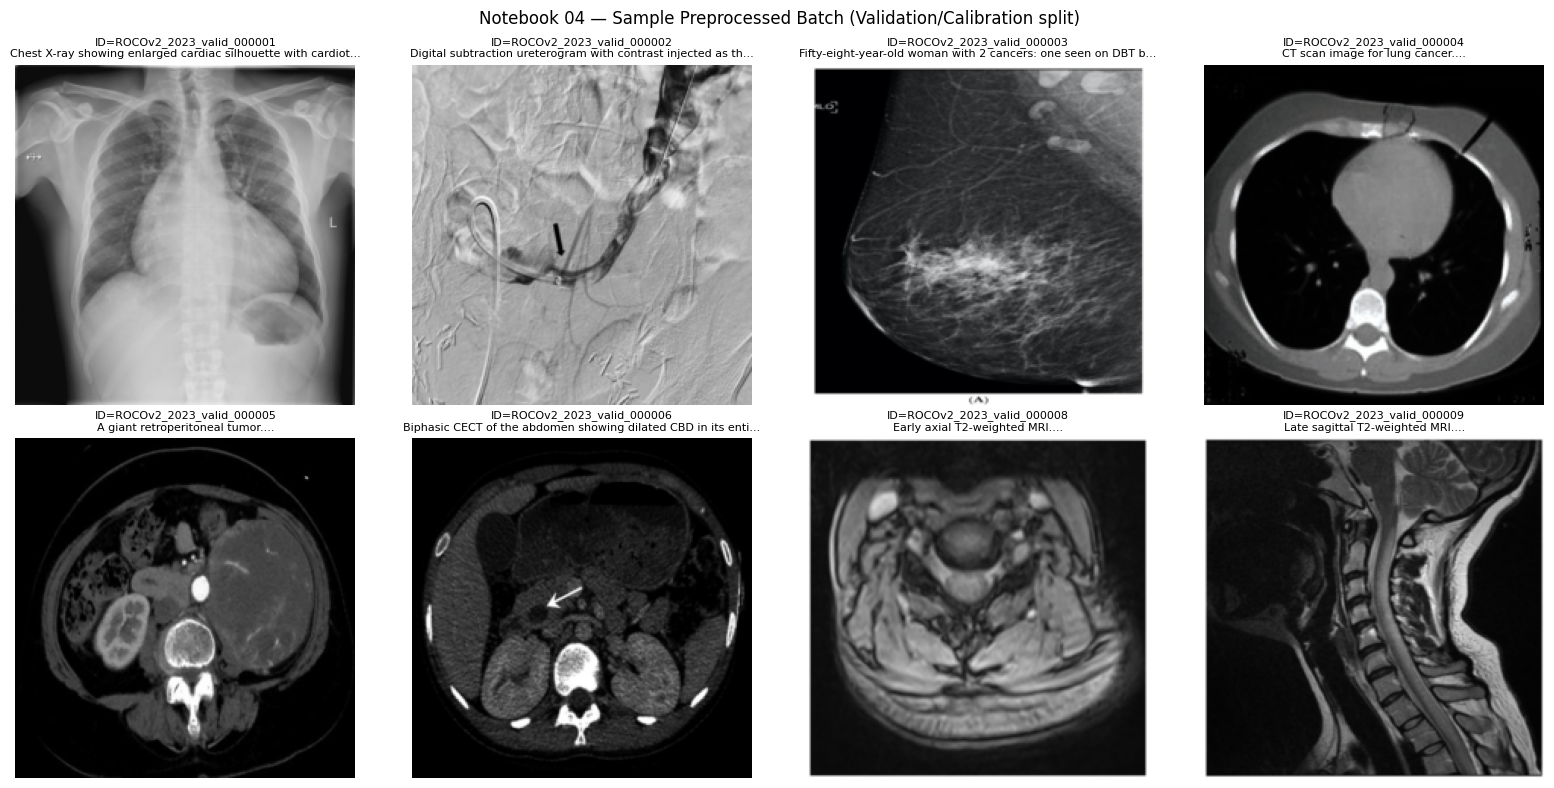

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/figures/sample_batch_grid.png


In [16]:
# ============================================================
# CELL 15 — SAMPLE BATCH VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

def denormalize(img_tensor, mean, std):
    mean_t = torch.tensor(mean).view(3, 1, 1)
    std_t = torch.tensor(std).view(3, 1, 1)
    return (img_tensor * std_t + mean_t).clamp(0, 1)

vis_batch = next(iter(dataloaders["validation"]))
n_show = min(8, vis_batch["image"].shape[0])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    if i >= n_show:
        ax.axis("off")
        continue
    img = denormalize(vis_batch["image"][i], CHANNEL_MEAN, CHANNEL_STD)
    ax.imshow(img.permute(1, 2, 0).numpy())
    caption_preview = str(
        split_dfs["validation"].set_index("ID").loc[vis_batch["id"][i], "Caption"]
    )[:60]
    ax.set_title(f"ID={vis_batch['id'][i]}\n{caption_preview}...", fontsize=8)
    ax.axis("off")

plt.suptitle("Notebook 04 — Sample Preprocessed Batch (Validation/Calibration split)")
plt.tight_layout()
plt.savefig(SAMPLE_BATCH_FIGURE_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", SAMPLE_BATCH_FIGURE_PATH)


## 15. Save the authoritative `preprocessing_config.json`

This file is treated the same way Notebook 02 treats `label_mapping.json`:
a **frozen, authoritative record** that later notebooks must read rather
than re-derive. Overwriting it silently would let preprocessing
methodology drift without a trace, so — matching Notebook 02's convention
— this refuses to overwrite an existing copy unless explicitly allowed.

In [17]:
# ============================================================
# CELL 16 — SAVE AUTHORITATIVE PREPROCESSING_CONFIG.JSON
# ============================================================

ALLOW_OVERWRITE = False

preprocessing_config = {
    "notebook": "04_ROCOv2_Preprocessing_Pipeline",
    "random_seed": SEED,
    "image": {
        "target_image_size": TARGET_IMAGE_SIZE,
        "channel_mean": CHANNEL_MEAN,
        "channel_std": CHANNEL_STD,
        "normalization_fit_split": "train",
        "train_augmentation": ["RandomRotation(10)", "ColorJitter(0.1, 0.1)"],
        "eval_augmentation": None,
        "flip_augmentation_disabled_reason": (
            "Label taxonomy encodes imaging orientation "
            "(Postero-Anterior / Anterior-Posterior / Transverse / Sagittal)."
        ),
        "zip_overlap_fallback_images_used": n_fallback,
    },
    "text": {
        "tokenizer_name": PUBMEDBERT_MODEL_NAME,
        "max_text_length": MAX_TEXT_LENGTH,
        "max_text_length_fit_split": "train",
        "max_text_length_train_p99_coverage_percent": coverage,
    },
    "dataloader": {
        "batch_size": BATCH_SIZE,
        "num_workers": NUM_WORKERS,
        "train_shuffle": True,
        "eval_shuffle": False,
    },
    "label_columns": LABEL_COLUMNS,
    "split_roles": {
        "train": "training + all preprocessing statistic fitting",
        "validation": "calibration — no preprocessing statistic fit on this split",
        "test": "untouched final evaluation — no preprocessing statistic fit on this split",
    },
}

if PREPROCESSING_CONFIG_PATH.exists() and not ALLOW_OVERWRITE:
    raise FileExistsError(
        f"Refusing to overwrite existing authoritative artifact:\n{PREPROCESSING_CONFIG_PATH}\n\n"
        "This protection prevents silent preprocessing-methodology drift. "
        "Remove/rename the old artifact or explicitly set ALLOW_OVERWRITE=True after review."
    )

with open(PREPROCESSING_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(preprocessing_config, f, indent=2)

print("Saved:", PREPROCESSING_CONFIG_PATH)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/preprocessing_config.json


## 16. Final integrity checks

Re-load every artifact independently from disk (not from in-memory
variables) and re-verify the core guarantees hold, matching the
independent-reload convention used in Notebooks 02 and 03.

In [18]:
# ============================================================
# CELL 17 — FINAL INTEGRITY CHECKS (independent reload)
# ============================================================

with open(PREPROCESSING_CONFIG_PATH, "r", encoding="utf-8") as f:
    reloaded_config = json.load(f)

assert reloaded_config["image"]["target_image_size"] == TARGET_IMAGE_SIZE
assert reloaded_config["text"]["max_text_length"] == MAX_TEXT_LENGTH
assert reloaded_config["text"]["tokenizer_name"] == PUBMEDBERT_MODEL_NAME
assert reloaded_config["image"]["normalization_fit_split"] == "train"
assert reloaded_config["text"]["max_text_length_fit_split"] == "train"

with open(TRAIN_CHANNEL_STATS_PATH, "r", encoding="utf-8") as f:
    reloaded_channel_stats = json.load(f)
assert reloaded_channel_stats["computed_on_split"] == "train"

reloaded_image_audit = pd.read_csv(IMAGE_PROPERTY_AUDIT_PATH)
assert int(reloaded_image_audit["Corrupt"].sum()) == 0

reloaded_caption_lengths = pd.read_csv(CAPTION_LENGTH_STATS_PATH)
assert set(reloaded_caption_lengths["Split"].unique()) == {"train", "validation", "test"}

assert determinism_check_passed

print("PASS — preprocessing_config.json reloads and matches in-memory decisions.")
print("PASS — Normalization statistics confirmed fit on Train split only.")
print("PASS — Zero corrupt images confirmed on reload.")
print("PASS — Caption length statistics cover all three splits.")
print("PASS — Train DataLoader determinism confirmed.")


PASS — preprocessing_config.json reloads and matches in-memory decisions.
PASS — Normalization statistics confirmed fit on Train split only.
PASS — Zero corrupt images confirmed on reload.
PASS — Caption length statistics cover all three splits.
PASS — Train DataLoader determinism confirmed.


## 17. Final artifact manifest and notebook status

In [19]:
# ============================================================
# CELL 18 — FINAL ARTIFACT MANIFEST
# ============================================================

artifact_paths = [
    IMAGE_PROPERTY_AUDIT_PATH,
    TRAIN_CHANNEL_STATS_PATH,
    CAPTION_LENGTH_STATS_PATH,
    PREPROCESSING_CONFIG_PATH,
    SAMPLE_BATCH_FIGURE_PATH,
]

manifest = []
for path in artifact_paths:
    manifest.append({
        "Artifact": path.name,
        "Path": str(path),
        "Exists": path.exists(),
        "Size_KB": round(path.stat().st_size / 1024, 2) if path.exists() else None,
    })

artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

missing = artifact_manifest_df.loc[~artifact_manifest_df["Exists"], "Path"].tolist()
status = "COMPLETE" if not missing else f"NOT READY — missing: {missing}"

print("\n" + "=" * 80)
print("NOTEBOOK 04 — PREPROCESSING PIPELINE")
print("=" * 80)

print("\nModels:")
print("  N/A — no model trained in this notebook. PubMedBERT tokenizer loaded (no weights fit).")

print("\nMetrics:")
print("  N/A — no evaluation metrics; this notebook produces pipeline artifacts only.")

print("\nFigures:")
print(f"  {SAMPLE_BATCH_FIGURE_PATH}")

print("\nTables:")
print(f"  {IMAGE_PROPERTY_AUDIT_PATH}")
print(f"  {CAPTION_LENGTH_STATS_PATH}")

print("\nLogs:")
print(f"  {TRAIN_CHANNEL_STATS_PATH}")
print(f"  {PREPROCESSING_CONFIG_PATH}")

print("\n" + "=" * 80)
print("NOTEBOOK 04 STATUS")
print("=" * 80)
print(f"\n[{status}]")
print("=" * 80)


,Artifact,Path,Exists,Size_KB
0,image_property_audit.csv,/content/drive/MyDrive/ROCOv2/Prepared/Preproc...,True,7163.08
1,train_channel_statistics.json,/content/drive/MyDrive/ROCOv2/Prepared/Preproc...,True,0.28
2,caption_length_statistics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Preproc...,True,2660.30
3,preprocessing_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Preproc...,True,1.70
4,sample_batch_grid.png,/content/drive/MyDrive/ROCOv2/Prepared/Preproc...,True,1189.73



NOTEBOOK 04 — PREPROCESSING PIPELINE

Models:
  N/A — no model trained in this notebook. PubMedBERT tokenizer loaded (no weights fit).

Metrics:
  N/A — no evaluation metrics; this notebook produces pipeline artifacts only.

Figures:
  /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/figures/sample_batch_grid.png

Tables:
  /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/image_property_audit.csv
  /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/caption_length_statistics.csv

Logs:
  /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/train_channel_statistics.json
  /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/preprocessing_config.json

NOTEBOOK 04 STATUS

[COMPLETE]
